# Logistic Regression as a GLM: Logits, Odds, and Odds Ratios

`m7` introduces logistic regression as a classifier. This notebook looks at the same model from the
statistical side of CSC604 Module 7:

- why a linear probability model is unsatisfactory;
- the logit link and the odds scale;
- logistic regression as a generalised linear model (GLM);
- how to interpret coefficients as log-odds and odds ratios;
- how to assess and report the model.

The example predicts whether a student is placed from `cgpa` and `score` in
`student_placement_data.csv`.

## Learning objectives

By the end of this notebook you can:

- write the logistic model in probability, odds, and log-odds form;
- explain the three components of a GLM;
- interpret a logistic coefficient and its odds ratio;
- compare a linear probability model with logistic regression;
- assess a logistic model with likelihood, pseudo $R^2$, AIC/BIC, and classification metrics.

## 1. From a line to a probability

A linear probability model (LPM) treats a binary outcome as if it were continuous:

$$
P(y=1\mid x) = x^\top\beta.
$$

This is easy to estimate with OLS, but it has problems:

- predicted probabilities can be below $0$ or above $1$;
- the error variance depends on $x$ (heteroscedasticity);
- the constant marginal effect is unrealistic near $0$ and $1$;
- a straight line cannot represent a bounded, S-shaped relationship.

Logistic regression keeps the linear predictor but maps it through the logistic (sigmoid) function:

$$
p(x) = P(y=1\mid x) = \frac{1}{1+e^{-(\beta_0+\beta_1x_1+\cdots+\beta_px_p)}}.
$$

The inverse of the sigmoid is the **logit**:

$$
\operatorname{logit}(p) = \ln\left(\frac{p}{1-p}\right) = \beta_0+\beta_1x_1+\cdots+\beta_px_p.
$$

So the model is linear on the log-odds scale, not on the probability scale.

## 2. Odds and odds ratios

For a probability $p$:

- **odds** $= \dfrac{p}{1-p}$;
- **log-odds** $= \ln(\text{odds})$;
- if $p=0.75$, the odds are $3$ ("three to one");
- if $p=0.5$, the odds are $1$ ("even").

For a coefficient $\beta_j$, increasing $x_j$ by one unit changes the log-odds by $\beta_j$, so the
odds are multiplied by

$$
\text{odds ratio (OR)} = e^{\beta_j}.
$$

- $OR=1$: no association on the odds scale;
- $OR>1$: the odds increase;
- $OR<1$: the odds decrease.

An odds ratio is **multiplicative**. It is not the same as a probability difference, and an OR of
$2$ does not mean "twice as likely" in probability terms.

## 3. Logistic regression as a GLM

A generalised linear model has three parts:

1. **Random component:** the response distribution. For binary $y$, use Bernoulli.
2. **Systematic component:** the linear predictor $\eta = X\beta$.
3. **Link function:** connects the mean of the response to the linear predictor. For logistic
   regression, $\eta = \operatorname{logit}(p)$.

Because the mean is a probability, the natural variance is $p(1-p)$. Estimation is by maximum
likelihood, not by minimising squared error. The likelihood for independent observations is

$$
L(\beta) = \prod_{i=1}^{n} p_i^{y_i}(1-p_i)^{1-y_i}.
$$

The model is fitted by maximising the log-likelihood (or minimising the negative log-likelihood).

In [1]:
import warnings

warnings.filterwarnings("ignore", message="A NumPy version")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

## 4. Load and split the data

We use a stratified split so that the training and test sets have similar placement rates.

In [2]:
df = pd.read_csv("student_placement_data.csv")
print("Rows, columns:", df.shape)
print("Placement rate:", round(df["placed"].mean(), 3))
df.head()

Rows, columns: (500, 3)
Placement rate: 0.754


,cgpa,score,placed
0,6.87,7.79,1
1,9.75,7.14,1
2,8.66,6.24,1
3,7.99,8.26,1
4,5.78,7.74,1


In [3]:
train, test = train_test_split(
    df,
    test_size=0.3,
    stratify=df["placed"],
    random_state=RANDOM_STATE,
)

print("Train:", train.shape, "Test:", test.shape)
print("Train placement rate:", round(train["placed"].mean(), 3))
print("Test placement rate:", round(test["placed"].mean(), 3))

Train: (350, 3) Test: (150, 3)
Train placement rate: 0.754
Test placement rate: 0.753


In [4]:
train[["cgpa", "score", "placed"]].describe().round(3)

,cgpa,score,placed
count,350.000,350.000,350.000
mean,7.573,6.913,0.754
std,1.483,1.142,0.431
min,5.030,5.020,0.000
25%,6.335,5.840,1.000
50%,7.630,6.880,1.000
75%,8.858,7.898,1.000
max,9.960,9.000,1.000


## 5. Fit the logistic model with statsmodels

`smf.logit` fits a binary logit model by maximum likelihood. The summary reports coefficients on
the **log-odds** scale, standard errors, Wald $z$ statistics, p-values, and confidence intervals.

In [5]:
logit_model = smf.logit("placed ~ cgpa + score", data=train).fit(disp=False)
logit_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                 placed   No. Observations:                  350
Model:                          Logit   Df Residuals:                      347
Method:                           MLE   Df Model:                            2
Date:                Wed, 18 Nov 2026   Pseudo R-squ.:                  0.3536
Time:                        21:26:28   Log-Likelihood:                -126.14
converged:                       True   LL-Null:                       -195.15
Covariance Type:            nonrobust   LLR p-value:                 1.064e-30
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -13.9634      1.709     -8.171      0.000     -17.313     -10.614
cgpa           0.9644      0.132      7.304      0.000       0.706       1.223
score          1.2340      0.174      7.107      0.000       0.894       1.574
==============================================================================
"""

In [6]:
print("Log-likelihood:", round(logit_model.llf, 3))
print("McFadden pseudo R-squared:", round(logit_model.prsquared, 3))
print("AIC:", round(logit_model.aic, 3))
print("BIC:", round(logit_model.bic, 3))
print("Likelihood-ratio statistic:", round(logit_model.llr, 3))
print("LR p-value:", logit_model.llr_pvalue)

Log-likelihood: -126.137
McFadden pseudo R-squared: 0.354
AIC: 258.274
BIC: 269.847
Likelihood-ratio statistic: 138.031
LR p-value: 1.0641998729299098e-30


The coefficients are additive on the log-odds scale:

- a one-unit increase in `cgpa` adds $\hat\beta_{\text{cgpa}}$ to the log-odds, holding `score`
  fixed;
- a one-unit increase in `score` adds $\hat\beta_{\text{score}}$ to the log-odds, holding `cgpa`
  fixed.

To make them interpretable on the odds scale, exponentiate them.

In [7]:
odds_ratios = pd.DataFrame(
    {
        "coefficient_log_odds": logit_model.params,
        "std_error": logit_model.bse,
        "p_value": logit_model.pvalues,
        "odds_ratio": np.exp(logit_model.params),
        "or_ci_lower": np.exp(logit_model.conf_int()[0]),
        "or_ci_upper": np.exp(logit_model.conf_int()[1]),
        "percent_change_in_odds": (np.exp(logit_model.params) - 1) * 100,
    }
)

odds_ratios.round(3)

,coefficient_log_odds,std_error,p_value,odds_ratio,or_ci_lower,or_ci_upper,percent_change_in_odds
Intercept,-13.963,1.709,0.0,0.000,0.000,0.000,-100.000
cgpa,0.964,0.132,0.0,2.623,2.025,3.398,162.320
score,1.234,0.174,0.0,3.435,2.444,4.827,243.491


### Reading the table

- An OR above $1$ means the odds of placement increase when the feature increases by one unit,
  holding the other feature fixed.
- An OR below $1$ means the odds decrease.
- The confidence interval is on the odds scale because we exponentiated both ends of the
  log-odds interval.
- A p-value tests $H_0:\beta_j=0$, which is equivalent to $H_0:OR_j=1$.

The intercept is the log-odds of placement when both `cgpa` and `score` are zero. That point is far
outside the observed data, so the intercept is mainly a mathematical baseline, not a useful
substantive quantity.

## 6. Confirm that this is a GLM

Fitting the same formula with `smf.glm(..., family=Binomial())` should give the same coefficients
and log-likelihood. The GLM framing makes the distribution and link explicit.

In [8]:
glm_model = smf.glm(
    "placed ~ cgpa + score",
    data=train,
    family=sm.families.Binomial(),
).fit()

comparison = pd.DataFrame(
    {
        "logit": logit_model.params,
        "glm_binomial": glm_model.params,
    }
)
comparison["difference"] = comparison["logit"] - comparison["glm_binomial"]
comparison.round(6)

,logit,glm_binomial,difference
Intercept,-13.963355,-13.963355,-0.0
cgpa,0.964396,0.964396,0.0
score,1.233992,1.233992,0.0


## 7. Predicted probabilities and log-odds

The fitted probability is a non-linear function of the features. The fitted log-odds is exactly
the linear predictor.

In [9]:
train_pred = logit_model.predict(train)
train_logodds_from_prob = np.log(train_pred / (1 - train_pred))

design_train = sm.add_constant(train[["cgpa", "score"]], has_constant="add")
train_logodds_from_model = design_train.to_numpy() @ logit_model.params.to_numpy()

check = pd.DataFrame(
    {
        "predicted_probability": train_pred,
        "logodds_from_probability": train_logodds_from_prob,
        "logodds_from_linear_predictor": train_logodds_from_model,
    }
)
check["difference"] = (
    check["logodds_from_probability"] - check["logodds_from_linear_predictor"]
)
check.head().round(8)

,predicted_probability,logodds_from_probability,logodds_from_linear_predictor,difference
20,0.948658,2.916536,2.916536,0.0
391,0.962148,3.235491,3.235491,0.0
120,0.862700,1.837898,1.837898,0.0
193,0.782908,1.282692,1.282692,-0.0
424,0.355728,-0.593956,-0.593956,-0.0


## 8. Compare with a linear probability model

The LPM is an OLS regression of the binary outcome on the same features. Its coefficients are
changes in probability, but its fitted values are not guaranteed to be valid probabilities.

In [10]:
lpm_model = smf.ols("placed ~ cgpa + score", data=train).fit()
lpm_train_pred = lpm_model.predict(train)
lpm_test_pred = lpm_model.predict(test)

print("LPM coefficient table:")
print(lpm_model.params.round(3).to_string())
print()
print("LPM fitted values on train:")
print("min =", round(lpm_train_pred.min(), 3), "max =", round(lpm_train_pred.max(), 3))
print("values below 0:", int((lpm_train_pred < 0).sum()))
print("values above 1:", int((lpm_train_pred > 1).sum()))

LPM coefficient table:
Intercept   -1.211
cgpa         0.122
score        0.151

LPM fitted values on train:
min = 0.179 max = 1.293
values below 0: 0
values above 1: 65


The LPM can produce impossible probabilities. It is still useful as a quick approximation and as a
benchmark, but logistic regression respects the $[0,1]$ range by construction.

Do **not** compare the LPM's AIC directly with the logistic AIC: the two models use different
likelihoods for different response distributions. Compare them on out-of-sample classification
metrics or on a common calibration measure instead.

## 9. Fit with scikit-learn and evaluate on the test set

Without regularisation, scikit-learn and statsmodels should agree closely on the coefficients
(up to numerical optimisation differences). We use `penalty=None` so the comparison is fair.

In [11]:
features = ["cgpa", "score"]

sk_logistic = LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000)
sk_logistic.fit(train[features], train["placed"])

sk_coefficients = pd.DataFrame(
    {
        "feature": ["intercept"] + features,
        "statsmodels": logit_model.params.values,
        "sklearn": np.r_[sk_logistic.intercept_, sk_logistic.coef_[0]],
    }
)
sk_coefficients.round(4)

,feature,statsmodels,sklearn
0,intercept,-13.9634,-13.9633
1,cgpa,0.9644,0.9644
2,score,1.2340,1.2340


In [12]:
test_prob = sk_logistic.predict_proba(test[features])[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

lpm_test_class = (lpm_test_pred >= 0.5).astype(int)
logit_test_class = test_pred

tn, fp, fn, tp = confusion_matrix(test["placed"], logit_test_class).ravel()

metrics = pd.DataFrame(
    {
        "linear_probability_model": {
            "accuracy": accuracy_score(test["placed"], lpm_test_class),
            "precision": precision_score(test["placed"], lpm_test_class, zero_division=0),
            "recall": recall_score(test["placed"], lpm_test_class, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "f1": f1_score(test["placed"], lpm_test_class, zero_division=0),
            "roc_auc": roc_auc_score(test["placed"], lpm_test_pred),
        },
        "logistic_regression": {
            "accuracy": accuracy_score(test["placed"], logit_test_class),
            "precision": precision_score(test["placed"], logit_test_class, zero_division=0),
            "recall": recall_score(test["placed"], logit_test_class, zero_division=0),
            "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
            "f1": f1_score(test["placed"], logit_test_class, zero_division=0),
            "roc_auc": roc_auc_score(test["placed"], test_prob),
        },
    }
).T

metrics.round(3)

,accuracy,precision,recall,specificity,f1,roc_auc
linear_probability_model,0.847,0.869,0.938,0.649,0.902,0.832
logistic_regression,0.853,0.889,0.920,0.649,0.904,0.833


In [13]:
confusion = pd.DataFrame(
    confusion_matrix(test["placed"], logit_test_class),
    index=["actual 0", "actual 1"],
    columns=["predicted 0", "predicted 1"],
)
confusion

,predicted 0,predicted 1
actual 0,24,13
actual 1,9,104


Accuracy alone can hide class imbalance. Always report the confusion matrix and at least one
measure that focuses on the positive class (precision or recall). The default threshold $0.5$ is a
choice, not a law: lower it to catch more positives, raise it to reduce false positives.

## 10. Marginal effects on the probability scale

A logistic coefficient is a change in log-odds. The change in probability depends on the starting
probability:

$$
\frac{\partial p}{\partial x_j} = p(1-p)\beta_j.
$$

At the mean predicted probability, we can compute an approximate average marginal effect.

In [14]:
mean_probability = logit_model.predict(train).mean()
marginal_at_mean = logit_model.params[["cgpa", "score"]] * mean_probability * (1 - mean_probability)

pd.DataFrame(
    {
        "coefficient_log_odds": logit_model.params[["cgpa", "score"]],
        "marginal_effect_at_mean_probability": marginal_at_mean,
    }
).round(4)

,coefficient_log_odds,marginal_effect_at_mean_probability
cgpa,0.9644,0.1787
score,1.2340,0.2287


Unlike the LPM coefficient, this marginal effect is not constant. It is largest near $p=0.5$ and
small near $p=0$ or $p=1$.

## 11. Visualise the fitted relationship

The plot fixes `score` at its median and varies `cgpa`. The left panel is on the probability scale;
the right panel is the same fitted relationship on the log-odds scale, where it is a straight line.

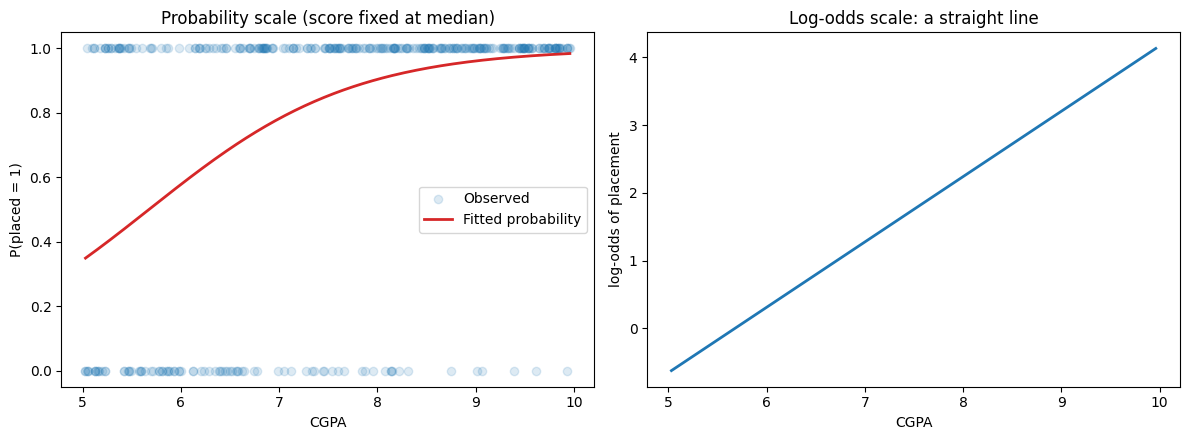

In [15]:
cgpa_grid = np.linspace(train["cgpa"].min(), train["cgpa"].max(), 200)
plot_data = pd.DataFrame(
    {
        "cgpa": cgpa_grid,
        "score": np.full_like(cgpa_grid, train["score"].median()),
    }
)
prob_grid = logit_model.predict(plot_data)
logodds_grid = np.log(prob_grid / (1 - prob_grid))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(train["cgpa"], train["placed"], alpha=0.15, label="Observed")
axes[0].plot(cgpa_grid, prob_grid, color="tab:red", linewidth=2, label="Fitted probability")
axes[0].set_xlabel("CGPA")
axes[0].set_ylabel("P(placed = 1)")
axes[0].set_title("Probability scale (score fixed at median)")
axes[0].legend()

axes[1].plot(cgpa_grid, logodds_grid, color="tab:blue", linewidth=2)
axes[1].set_xlabel("CGPA")
axes[1].set_ylabel("log-odds of placement")
axes[1].set_title("Log-odds scale: a straight line")

plt.tight_layout()
plt.show()

## 12. What to report

A complete report of this model would include:

1. the model formula and the link function;
2. coefficients on the log-odds scale with confidence intervals;
3. odds ratios with confidence intervals, clearly labelled as multiplicative;
4. a measure of overall fit (log-likelihood, McFadden pseudo $R^2$, AIC/BIC);
5. out-of-sample classification metrics and a confusion matrix;
6. the threshold used for classification;
7. a caution that association is not causation.

Pseudo $R^2$ values in logistic regression are not interpreted like OLS $R^2$. McFadden values
between roughly $0.2$ and $0.4$ often indicate a useful model, but the threshold depends on the
problem.

## 13. Cautions

- **Linearity on the log-odds scale.** The model assumes each feature is linear in the logit.
- **Independence.** Observations should not be clustered or repeated without a suitable model.
- **Separation.** A feature that perfectly predicts the outcome can make maximum-likelihood
  estimates diverge.
- **Influential observations.** A few points can change the fit; inspect residuals and leverage.
- **Calibration.** Good discrimination (ROC-AUC) does not guarantee good calibration.
- **Odds ratios are not risk ratios.** They are often farther from $1$ than the corresponding
  probability ratio, especially for common outcomes.
- **Causality.** A coefficient describes association under the model, not a causal effect.

## Summary

- Logistic regression models the log-odds as a linear function of the features.
- It is a GLM with a Bernoulli random component and a logit link.
- Exponentiating a coefficient gives an odds ratio.
- Predictions are probabilities in $(0,1)$; coefficients are changes in log-odds.
- Marginal effects on the probability scale depend on the current probability.
- Evaluate with likelihood-based summaries and out-of-sample classification metrics.

## Exercises

1. Fit a model with only `cgpa`. Compare its AIC and test ROC-AUC with the two-feature model.
2. Add an interaction term `cgpa * score`. Does it improve out-of-sample performance?
3. Compute odds ratios and confidence intervals for your interaction model and interpret them.
4. Change the classification threshold from $0.5$ to $0.3$ and $0.7$. Tabulate precision, recall,
   and specificity.
5. Plot a calibration curve for the logistic model on the test set.
6. Explain why an odds ratio of $2$ is not the same as a probability of $0.5$ versus $0.25$.